In [1]:
# === Google Colab 自動環境セットアップ ===
# Google Colab で実行する場合は、以下のセルを実行してリポジトリのクローンと環境構築を行ってください。
# ローカル環境で実行する場合は、このセルをスキップしてそのまま次のセルへ進んでください。

import os
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    print("Google Colab 環境を検出しました。リポジトリをセットアップします...")
    !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !cmake -B build
    !cmake --build build --target ch10_draggable_layer
    sys.path.insert(0, str(Path.cwd()))
    print("環境セットアップが完了しました。")
else:
    print("ローカル実行環境です。")
    project_root = Path.cwd().resolve()
    if project_root.name == "10":
        project_root = project_root.parent
    if str(project_root) not in sys.path:
        sys.path.insert(0, str(project_root))
    print(f"プロジェクトルート: {project_root}")

ローカル実行環境です。
プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 10.7 ウィンドウだけドラッグ移動 (Draggable Layer Flags) (`osbook_day10g`)

本節では、第10.6節（`osbook_day10f`）で実装したウィンドウドラッグ機能に残存していた **「デスクトップ背景レイヤ（`bgwindow`）やコンソールレイヤ（`console_window`）までクリック一発でドラッグできてしまうバグ」** を解決し、**ドラッグを許可した通常の GUI ウィンドウだけを安全に移動できるアーキテクチャ** を完成させます。

---

## 🎯 本節の学習目標と技術課題

前節（第10.6節 `osbook_day10f`）では、`LayerManager::FindLayerByPosition` と `MouseObserver` の 4 状態ステートマシン（FSM）によって、マウス左ボタンのドラッグ操作に追従して `Hello Window` を動かせるようになりました。しかし同時に、次の深刻な不具合が顕在化していました：

1. **すべてのレイヤが無差別にドラッグ対象になってしまう**:
   - `FindLayerByPosition(mouse_position, mouse_layer_id)` は「`mouse_layer_id` を除く、`Window` を持つ可視レイヤ」をすべてヒット対象として返します。
   - MikanOS のデスクトップ背景（`bglayer_id`）やコンソール（`console->LayerID()`）も内部的には `Window` インスタンスを持つ `Layer` として管理されているため、画面の空き領域をクリックしてドラッグすると、**デスクトップ背景ごと画面外へ引きずられてしまい、背後の未描画 VRAM 領域（古い残像）が露出** してしまいました。
2. **「視覚上のヒット判定」と「ドラッグ許可属性」の分離**:
   - 解決策として `Layer` クラスに `draggable_` フラグを導入しますが、**「どのレイヤをデフォルトでドラッグ可能にするか（ブラックリスト方式 vs ホワイトリスト方式）」** および **「`IsDraggable()` チェックを `FindLayerByPosition` の中に置くか、`MouseObserver` 側に置くか」** という 2 つの重要なソフトウェア設計上の意思決定が問われます。

### 💡 本節の変更ファイル一覧 (`osbook_day10f` → `osbook_day10g`)

| ファイル | 主な変更内容 |
|---|---|
| `kernel/layer.hpp` | `Layer` クラスに `SetDraggable(bool)` / `IsDraggable() const` メソッドとメンバ変数 `bool draggable_{false};` を追加（`pos_{}`・`window_{}` の均一初期化も統一） |
| `kernel/layer.cpp` | `Layer::SetDraggable` と `Layer::IsDraggable` を実装（Fluent Interface `*this` 返却） |
| `kernel/main.cpp` | `MouseObserver` で `if (layer && layer->IsDraggable())` ガードを追加し、`KernelMainNewStack` で `main_window_layer_id` のみ `.SetDraggable(true)` を指定 |

### 専門用語・設計原則の併記
- **NSDMI** (*Non-Static Data Member Initializer*, 非静的データメンバ初期化子): C++11 以降でクラス定義内のメンバ宣言に直接 `pos_{}` や `draggable_{false}` のように初期値を記述し、初期化漏れによる未定義動作（UB）を防ぐ構文。
- **Fail-Safe Default / Whitelist Policy** (*フェイルセーフ既定値 / ホワイトリスト方式*): 明示的に許可（`.SetDraggable(true)`）された対象だけに行動を許し、未知・新規の要素は安全側（`false` = 固定）に倒す設計思想。
- **Fluent Interface** (*流暢なインターフェース / メソッドチェーン*): セッターが `Layer&`（`*this`）を返すことで、`NewLayer().SetWindow(...).SetDraggable(true).Move(...).ID()` と連鎖記述できる API 設計。
- **Short-Circuit Evaluation** (*短絡評価*): 論理積 `A && B` において左辺 `A` が偽（`nullptr`）のとき右辺 `B` を評価しない C++ の保証。ヌルポインタ間接参照を防ぐ。
- **Single Responsibility Principle (SRP)** (*単一責任の原則*) & **Occlusion** (*遮蔽*): ヒットテストは純粋に最前面の視覚レイヤ特定のみを担い、ドラッグ可否判定は呼び出し側に委ねることで、手前の非ドラッグレイヤが背後ウィンドウへの貫通クリック（Click-Through）を正しく遮蔽する設計。

---

## 1. `osbook_day10f` 背景ドラッグバグの根本原因解剖

第10.6節の時点における MikanOS デスクトップのレイヤスタック（Z オーダー昇順：`layer_stack_[0..3]`）を振り返ります。

| Z 順 | `Layer::ID()` | 役割 (`main.cpp`) | `Window` の有無 | `10.6` (`day10f`) でのクリック時挙動 | 本来望ましい挙動 (`day10g`) |
|:---:|:---:|---|:---:|---|---|
| `0` | `bglayer_id` (`1`) | デスクトップ背景＋タスクバー (`320×200` / `1024×768`) | **あり** (`bgwindow`) | 掴まれてしまい背景ごと動く（**バグ**） | クリックしても**動かない（固定）** |
| `1` | `console->LayerID()` (`2`) | カーネルログ出力コンソール (`console_window`) | **あり** (`console_window`) | 掴まれてしまいコンソールが動く（**意図せず動く**） | 現段階では**動かない（固定）** |
| `2` | `main_window_layer_id` (`3`) | カウンタ表示 GUI ウィンドウ (`Hello Window`) | **あり** (`main_window`) | 掴んでドラッグ移動できる | 掴んで**ドラッグ移動できる** |
| `3` | `mouse_layer_id` (`4`) | マウスカーソル (`mouse_window`) | **あり** (`mouse_window`) | `exclude_id` で走査から除外 | `exclude_id` で走査から除外 |

### なぜ背景レイヤが動くと画面が壊れるのか？

`LayerManager::MoveRelative(bglayer_id, posdiff)` が実行されると、内部では次の 2 段階の再描画が走ります（第10.4節・10.5節参照）：

1. `Draw({old_pos, window_size})`：移動前の領域を描画し直すが、最背面レイヤ（`Z = 0`）が画面端から内側にズレてしまうと、**露出した外周領域（例えば画面右端や下端）にはどのレイヤも描画されない** ため、`back_buffer_` 上に前回のフレームの残像や初期値 `0`（黒色）がそのまま残ってしまいます。
2. したがって、画面全体を覆う背景レイヤや、固定 UI として設計されたコンソールレイヤは、**「マウスで掴んで動かす対象ではない」という属性（メタデータ）をレイヤ自身に持たせて制御する** 必要があります。

```mermaid
flowchart TD
    Click["左ボタン押下開始 (!prev && curr)"] --> Find["FindLayerByPosition(mouse_position, mouse_layer_id)"]
    Find --> CheckNull{"layer != nullptr ?"}
    CheckNull -- "No (画面外など)" --> Ignore["mouse_drag_layer_id = 0 (無視)"]
    CheckNull -- "Yes" --> CheckDrag{"layer->IsDraggable() ?"}
    CheckDrag -- "false (DesktopBG / Console)" --> Reject["ドラッグ拒否: mouse_drag_layer_id = 0 のまま固定"]
    CheckDrag -- "true (HelloWindow)" --> Accept["ドラッグ開始: mouse_drag_layer_id = layer->ID()"]
```

---

## 2. `Layer` クラスの拡張設計と C++ メンバ初期化の徹底 (`layer.hpp`, `layer.cpp`)

`osbook_day10g` における `kernel/layer.hpp` と `kernel/layer.cpp` の差分を 1 行ずつ確認しましょう。

### 2.1 `kernel/layer.hpp` の変更差分

```cpp
class Layer {
 public:
  Layer(unsigned int id = 0);
  unsigned int ID() const;

  Layer& SetWindow(const std::shared_ptr<Window>& window);
  std::shared_ptr<Window> GetWindow() const;
  Vector2D<int> GetPosition() const;
  /** @brief true でレイヤーがドラッグ移動可能となる。 */
  Layer& SetDraggable(bool draggable);
  /** @brief レイヤーがドラッグ移動可能なら true を返す。 */
  bool IsDraggable() const;

  Layer& Move(Vector2D<int> pos);
  Layer& MoveRelative(Vector2D<int> pos_diff);
  void DrawTo(FrameBuffer& screen, const Rectangle<int>& area) const;

 private:
  unsigned int id_;
  Vector2D<int> pos_{};
  std::shared_ptr<Window> window_{};
  bool draggable_{false};
};
```

### 2.2 `kernel/layer.cpp` の変更差分

```cpp
Layer& Layer::SetDraggable(bool draggable) {
  draggable_ = draggable;
  return *this;
}

bool Layer::IsDraggable() const {
  return draggable_;
}
```

### 2.3 C++ 言語仕様・設計の重要ポイント 4 点

1. **NSDMI（非静的データメンバ初期化子）によるゼロ初期化の徹底**:
   - `osbook_day10f` では `Vector2D<int> pos_;` と `std::shared_ptr<Window> window_;` でしたが、`osbook_day10g` では **`pos_{}`**, **`window_{}`**, **`draggable_{false}`** とすべて波括弧 `{}` によるメンバ初期化子が付与されました。
   - もし `bool draggable_;` のように初期化子を付け忘れると、ヒープ確保された `Layer` インスタンスの `draggable_` には **未初期化ゴミ値（Indeterminate Value）** が入り、x86-64 上でバイト値が `0` 以外だった場合に `true` と判定されて **「背景が動いたり動かなかったりする極めて厄介な不定バグ」** になります。`{false}` により全インスタンスが確実に `false` で誕生します。
2. **ホワイトリスト方式（Fail-Safe Default = `false`）の合理性**:
   - もしデフォルトを `true`（ブラックリスト方式）にすると、今後タスクバー・通知バナー・起動スプラッシュ・デスクトップウィジェットなど新しい固定レイヤを追加するたびに `.SetDraggable(false)` を書き忘れるリスクを抱えます。
   - 逆にデフォルトを `false`（ホワイトリスト方式）にしておけば、仮に `.SetDraggable(true)` を書き忘れたとしても「新ウィンドウが動かない」という即座に気づける無害な症状にとどまり、背景破壊バグは絶対に再発しません。
3. **Fluent Interface（メソッドチェーン）との一貫性**:
   - `SetDraggable(bool)` の戻り値型が `void` ではなく **`Layer&`** で `return *this;` を返すため、`SetWindow`, `SetDraggable`, `Move`, `ID` を 1 つの式で連結できます。
4. **`Layer` クラスのメモリレイアウトとアライメント（x86-64 System V ABI）**:
   - `id_` (`unsigned int`, 4B, offset `0x00`) → `pos_` (`Vector2D<int>`, 8B, offset `0x04`) → 4B パディング (`0x0C..0x0F`, 8B アライメント調整) → `window_` (`std::shared_ptr<Window>`, 16B, offset `0x10..0x1F`) → `draggable_` (`bool`, 1B, offset `0x20`) → 末尾パディング 7B → **`sizeof(Layer) == 40` バイト**（8 バイトアライメント）。
   - ※環境や標準ライブラリ（libc++ vs libstdc++）により `shared_ptr` のアライメントに合わせ構造体サイズが 40 バイトに収まります。

図版を保存しました: 10/result/fig10_19_layer_draggable_flag_architecture.png


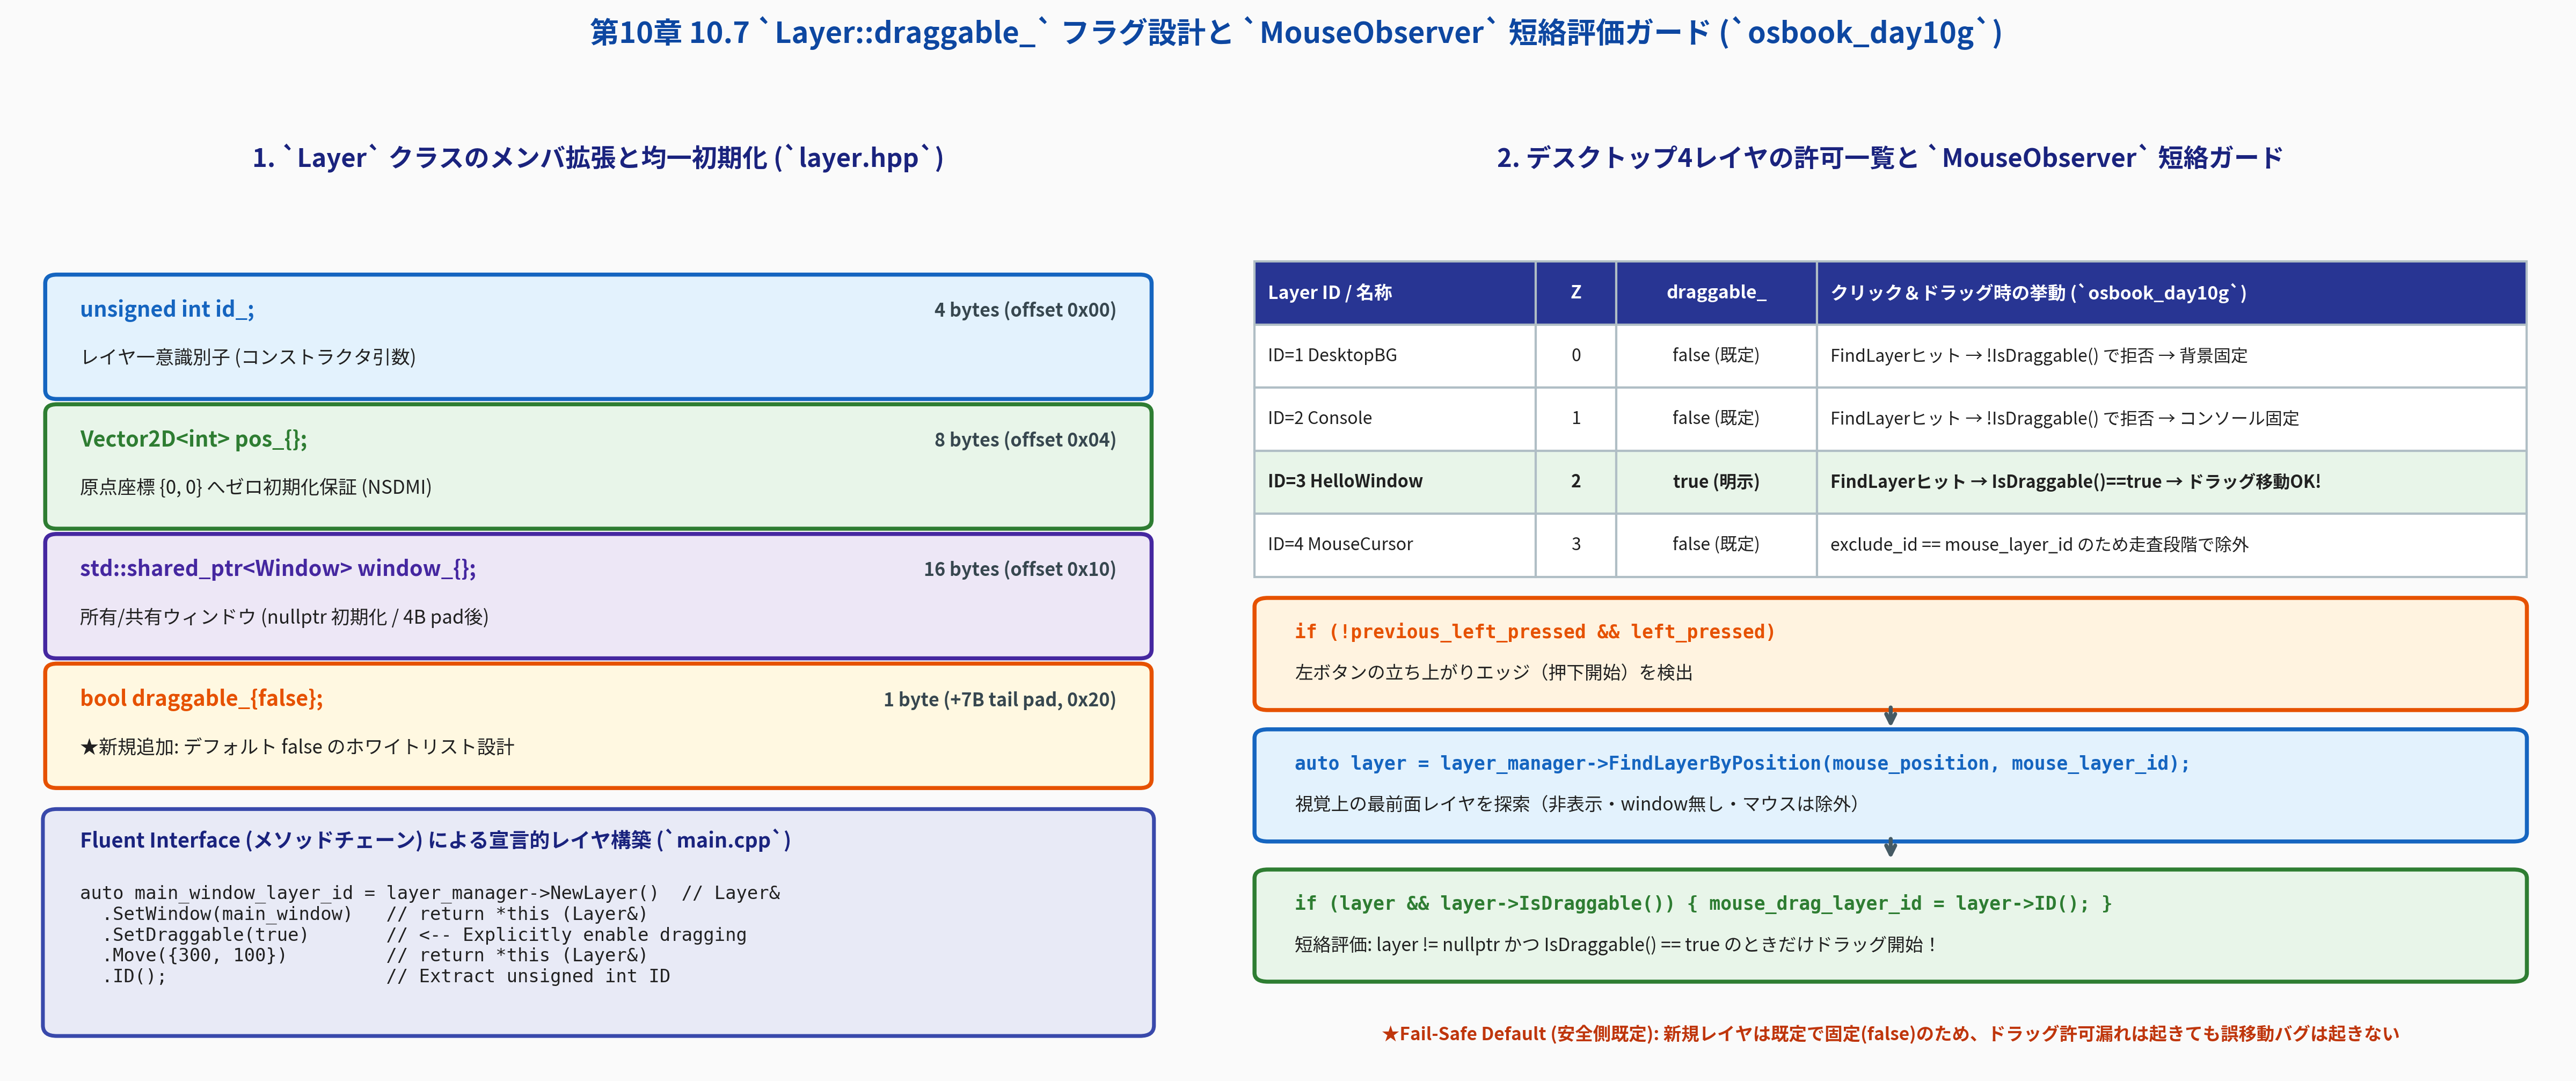

In [2]:
# 図版 10.19: Layer::draggable_ フラグのメモリ構造、NSDMI、および MouseObserver 短絡ガードの可視化
from IPython.display import Image, display
from common import generate_ch10_19_layer_draggable_flag_architecture

fig19_path = generate_ch10_19_layer_draggable_flag_architecture()
print(f"図版を保存しました: {fig19_path}")
display(Image(filename=str(fig19_path)))

---

## 3. `MouseObserver` のガードと単一責任の原則 (SRP) (`kernel/main.cpp`)

`osbook_day10g` における `kernel/main.cpp` の変更は次の 2 箇所だけです。

### 3.1 `MouseObserver` における短絡評価ガード

```cpp
  const bool previous_left_pressed = (previous_buttons & 0x01);
  const bool left_pressed = (buttons & 0x01);
  if (!previous_left_pressed && left_pressed) {
    auto layer = layer_manager->FindLayerByPosition(mouse_position, mouse_layer_id);
    if (layer && layer->IsDraggable()) {
      mouse_drag_layer_id = layer->ID();
    }
  } else if (previous_left_pressed && left_pressed) {
```

- **短絡評価（Short-Circuit Evaluation）によるヌルポインタ防御**:
  `FindLayerByPosition` は条件に合うレイヤが見つからない場合（例：背景を外した画面外等）に `nullptr` を返します。`if (layer && layer->IsDraggable())` と書くことで、左辺 `layer` が `nullptr`（偽）であれば右辺 `layer->IsDraggable()` は絶対に実行されず、ページフォルト（`#PF`）によるカーネルパニックを防ぎます。

### 3.2 `KernelMainNewStack` における明示的ドラッグ許可

```cpp
  auto bglayer_id = layer_manager->NewLayer()
    .SetWindow(bgwindow)
    .Move({0, 0})
    .ID();
  mouse_layer_id = layer_manager->NewLayer()
    .SetWindow(mouse_window)
    .Move(mouse_position)
    .ID();
  auto main_window_layer_id = layer_manager->NewLayer()
    .SetWindow(main_window)
    .SetDraggable(true)
    .Move({300, 100})
    .ID();
  console->SetLayerID(layer_manager->NewLayer()
    .SetWindow(console_window)
    .Move({0, 0})
    .ID());
```

---

### 3.3 【重要設計論】なぜ `FindLayerByPosition` の中で `IsDraggable()` をチェックしないのか？

初心者・中級者がよく思いつく代替案に、**「`FindLayerByPosition` のラムダ述語 `pred` の中に `if (!layer->IsDraggable()) return false;` を書けば、`MouseObserver` を変えなくて済むのでは？」** というアイデアがあります。

しかし、MikanOS があえて **`FindLayerByPosition` を変更せず、呼び出し側（`MouseObserver`）で `layer->IsDraggable()` をチェックした** のには、OS/GUI アーキテクチャ上の極めて深い理由があります。

| 比較観点 | MikanOS の設計 (`MouseObserver` 側で判定) | アンチパターン (`FindLayerByPosition` 内でスキップ) |
|---|---|---|
| **手前の非ドラッグレイヤによる遮蔽 (Occlusion)** | **正しく遮蔽する**：手前の固定パネル上でクリックすれば固定パネルがヒットし、ドラッグは開始されない（`drag_id = 0`） | **Click-Through（貫通）バグ発生**：手前の固定パネルを素通りして、背後で隠れているドラッグ可能ウィンドウを誤って掴んで動かしてしまう！ |
| **単一責任の原則 (SRP)** | `FindLayerByPosition` は「指定座標の最前面**視覚レイヤ**を返す」という純粋な幾何関数として再利用可能 | 「ドラッグ可能なレイヤ専用」に機能が汚染され、将来のクリックイベント・閉じるボタン・フォーカス切替に使えなくなる |
| **将来の拡張性（第15章・第30章）** | 固定パネルやコンソールをクリックしてフォーカス（アクティブウィンドウ）だけ切り替える処理へ自然に拡張可能 | 非ドラッグレイヤのクリックイベントを一切受け取れなくなる |

この「遮蔽（Occlusion）vs 貫通（Click-Through）」の違いを、図版 10.20 と Python シミュレーションで定量的に検証しましょう！

図版を保存しました: 10/result/fig10_20_occluding_non_draggable_click_through_analysis.png


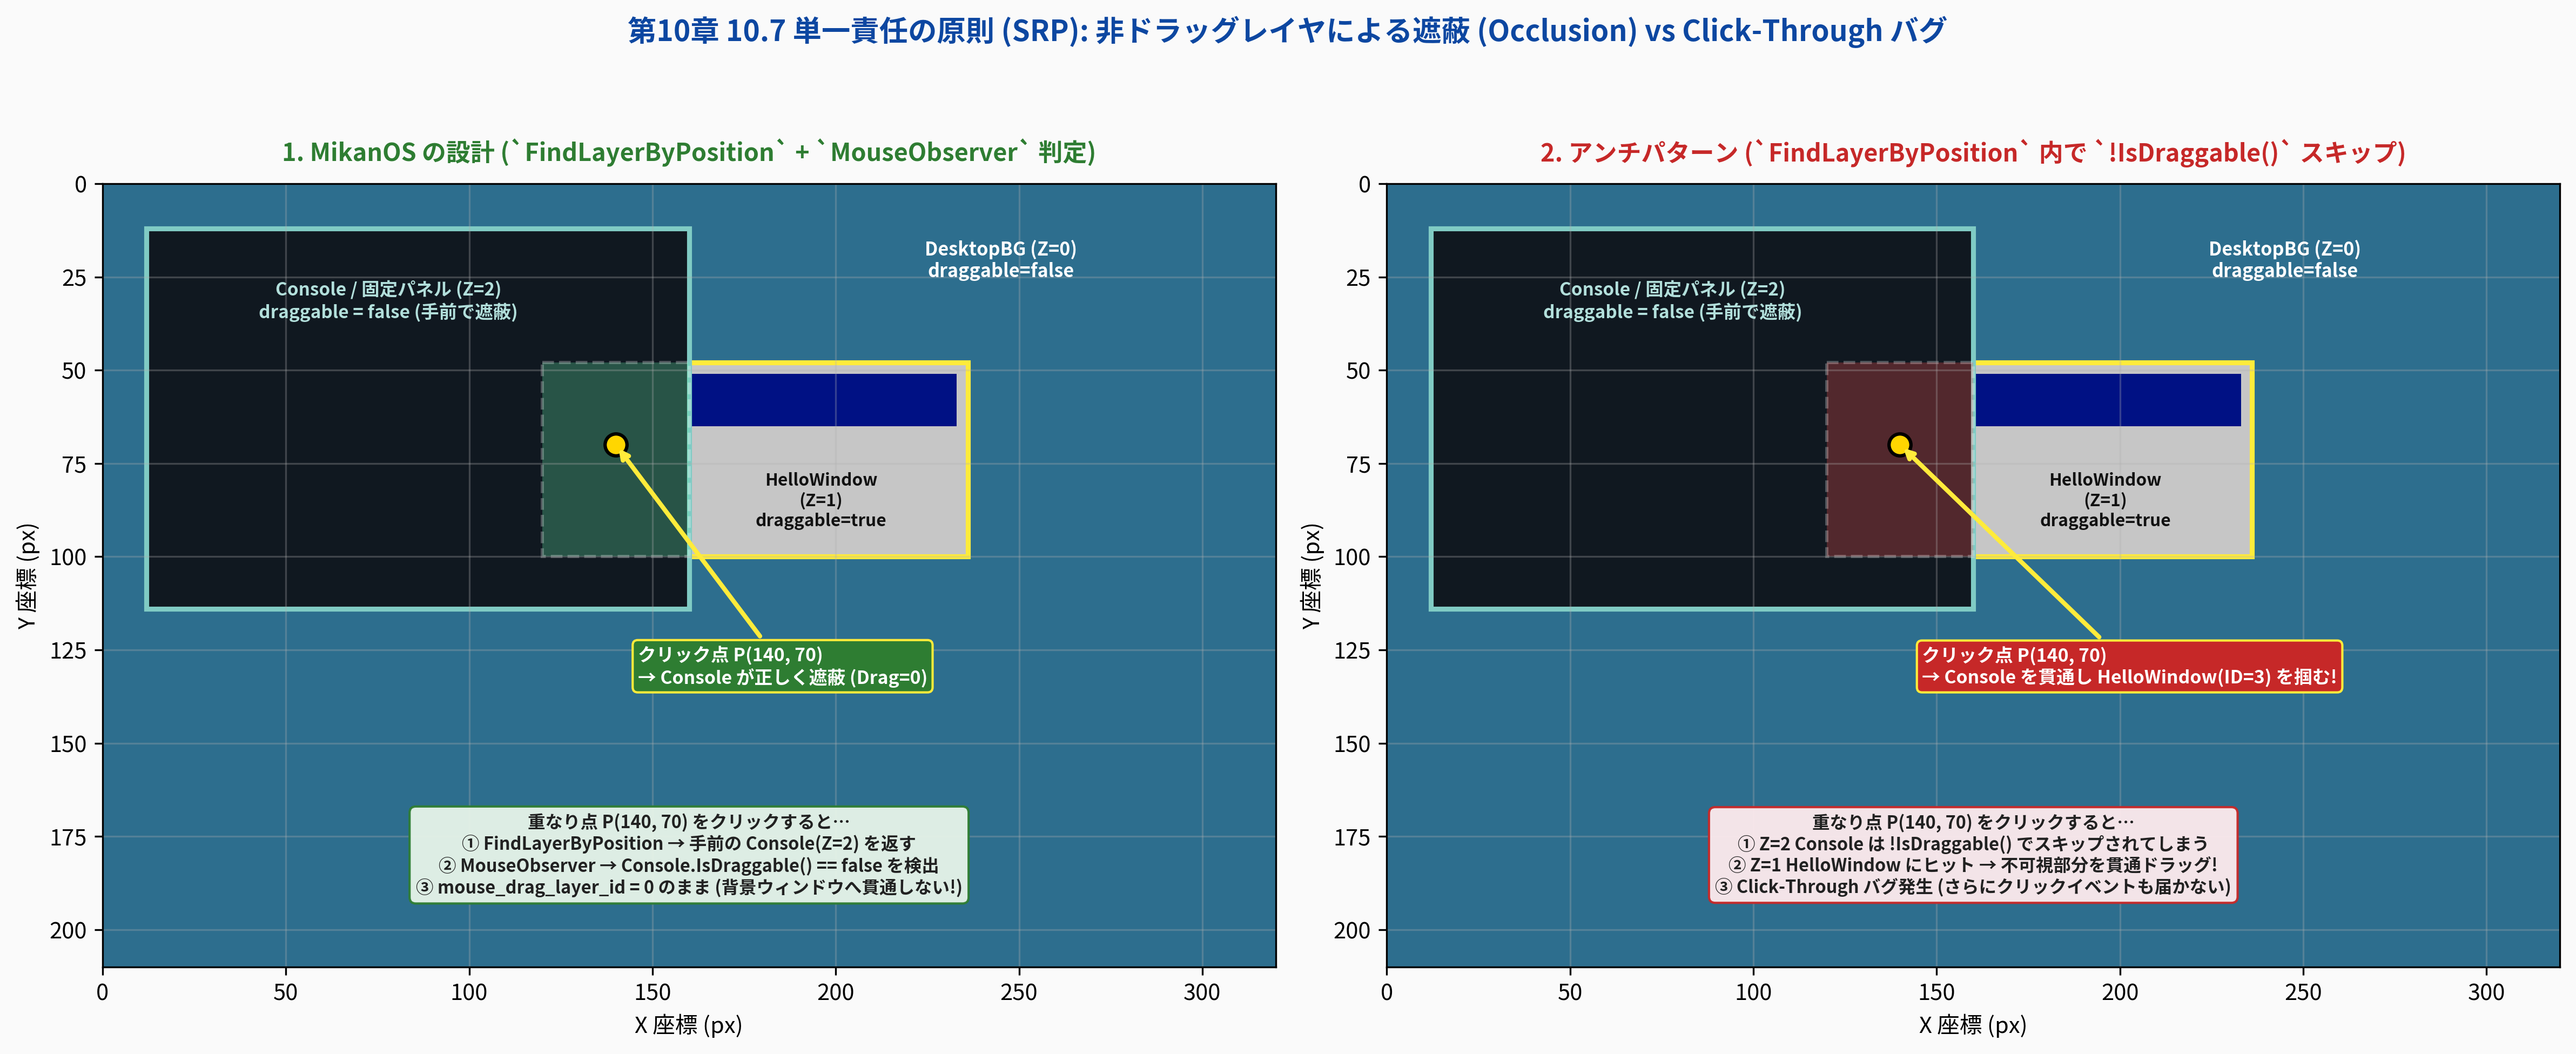

In [3]:
# 図版 10.20: 単一責任の原則 (SRP) に基づく遮蔽 (Occlusion) vs Click-Through 貫通バグの比較図
from common import generate_ch10_20_occluding_non_draggable_click_through_analysis

fig20_path = generate_ch10_20_occluding_non_draggable_click_through_analysis()
print(f"図版を保存しました: {fig20_path}")
display(Image(filename=str(fig20_path)))

In [4]:
# 対話型 Python 実験 1: ホワイトリスト初期値・SRP遮蔽 vs Click-Through バグの定量検証
from common import DraggableLayerSim

sim = DraggableLayerSim.create_mikanos_desktop_sim(320, 200, init_mouse_pos=(140, 70))

print("=== 1. 各レイヤの初期 draggable_ フラグ (Fail-Safe Default 確認) ===")
for lid in sim.db_sim.layer_stack:
    spec = sim.db_sim.layers[lid]
    print(f"  ID={lid} ({spec.name:12s}): draggable = {sim.is_draggable(lid)}")

assert sim.is_draggable(1) is False  # DesktopBG
assert sim.is_draggable(2) is False  # Console
assert sim.is_draggable(3) is True   # HelloWindow
assert sim.is_draggable(4) is False  # MouseCursor

print("\n=== 2. 遮蔽 (Occlusion) vs Click-Through 実験 ===")
# Console (ID=2, draggable=False) を HelloWindow (ID=3, draggable=True) の手前 (Z=2) に配置
sim.up_down(2, 2)  # stack: [1(BG), 3(HelloWindow), 2(Console), 4(Mouse)]
overlap_pt = (140, 70)

hit_mikan, trace_mikan = sim.find_layer_by_position(overlap_pt, exclude_id=4, naive_filter_draggable=False)
hit_bug, trace_bug = sim.find_layer_by_position(overlap_pt, exclude_id=4, naive_filter_draggable=True)

print(f"クリック座標 {overlap_pt} (Console と HelloWindow の重複領域):")
print(f"  [MikanOS設計] FindLayerByPosition -> ID={hit_mikan} ({sim.db_sim.layers[hit_mikan].name}), "
      f"IsDraggable={sim.is_draggable(hit_mikan)}")
print(f"  [アンチパターン] naive_filter_draggable=True -> ID={hit_bug} ({sim.db_sim.layers[hit_bug].name}), "
      f"IsDraggable={sim.is_draggable(hit_bug)}  <-- 背後を貫通してしまう!")

# MikanOS設計で実際にマウス押下すると drag_id == 0 のまま保護される
ev = sim.mouse_observer(0x01, 0, 0)
print(f"  MouseObserver 結果: {ev.transition} | mouse_drag_layer_id = {ev.drag_layer_id}")
assert ev.hit_layer_id == 2
assert ev.drag_accepted is False
assert ev.drag_layer_id == 0

=== 1. 各レイヤの初期 draggable_ フラグ (Fail-Safe Default 確認) ===
  ID=1 (DesktopBG   ): draggable = False
  ID=2 (Console     ): draggable = False
  ID=3 (HelloWindow ): draggable = True
  ID=4 (MouseCursor ): draggable = False

=== 2. 遮蔽 (Occlusion) vs Click-Through 実験 ===
クリック座標 (140, 70) (Console と HelloWindow の重複領域):
  [MikanOS設計] FindLayerByPosition -> ID=2 (Console), IsDraggable=False
  [アンチパターン] naive_filter_draggable=True -> ID=3 (HelloWindow), IsDraggable=True  <-- 背後を貫通してしまう!
  MouseObserver 結果: RISING_EDGE (Rejected: !IsDraggable) | mouse_drag_layer_id = 0


---

## 4. 全 4 レイヤのドラッグ挙動シミュレーションと VRAM 完全性検証

`osbook_day10g` を適用した MikanOS デスクトップで、次の 3 つのシナリオをフレームバッファレベルでシミュレーション検証します：

1. **シナリオ 1（背景ドラッグ試行）**: 空きデスクトップ `(250, 140)` を左クリックして `(-40, -28)` ドラッグ → `FindLayerByPosition` は `DesktopBG (ID=1)` を返すが、`IsDraggable() == false` のため `mouse_drag_layer_id = 0` のまま拒否され、背景座標は `(0, 0)` に完全固定されます。
2. **シナリオ 2（コンソールドラッグ試行）**: コンソール領域 `(50, 50)` を左クリックして `(+30, +25)` ドラッグ → `Console (ID=2)` も `IsDraggable() == false` のため移動しません。
3. **シナリオ 3（HelloWindow ドラッグ成功）**: `HelloWindow (ID=3)` 上の `(180, 66)` を左クリックしてドラッグ → `.SetDraggable(true)` が有効なため、画面端クランプ時の `posdiff` 同期を含めて滑らかに追従移動し、かつダブルバッファリングにより VRAM と `back_buffer_` が全ピクセル一致します。

図版を保存しました: 10/result/fig10_21_draggable_layer_desktop_simulation.png


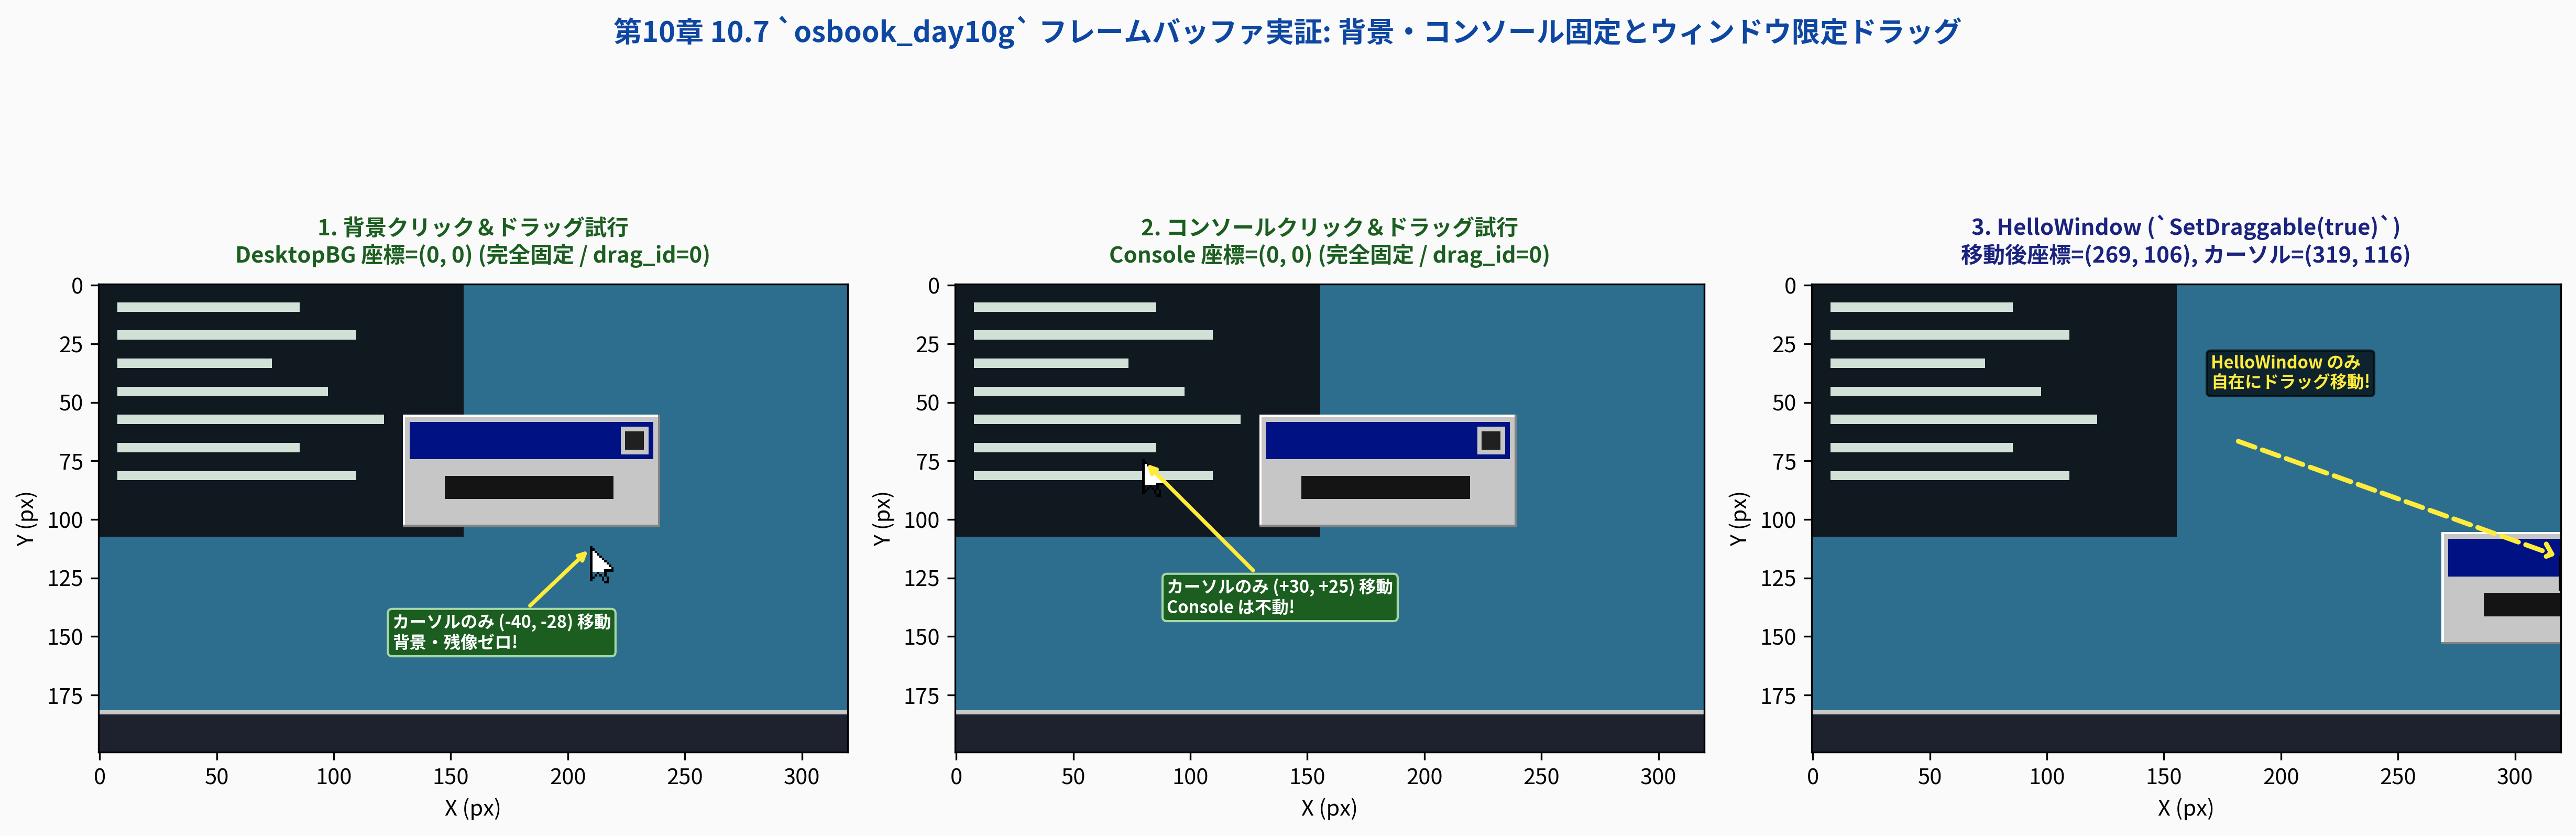

In [5]:
# 図版 10.21: osbook_day10g 全 3 シナリオのフレームバッファ出力比較 (背景固定・コンソール固定・HelloWindow移動)
from common import generate_ch10_21_draggable_layer_desktop_simulation

fig21_path = generate_ch10_21_draggable_layer_desktop_simulation()
print(f"図版を保存しました: {fig21_path}")
display(Image(filename=str(fig21_path)))

In [6]:
# 対話型 Python 実験 2: 3シナリオの連続イベントトレースと VRAM == back_buffer_ 一致証明
import numpy as np

sim_e2e = DraggableLayerSim.create_mikanos_desktop_sim(320, 200, init_mouse_pos=(250, 140))

events = [
    ("背景クリック",         0x01,   0,   0),
    ("背景ドラッグ試行",     0x01, -40, -28),
    ("左ボタン解放",         0x00,   0,   0),
    ("コンソールへ移動1",    0x00,-100, -62),
    ("コンソールへ移動2",    0x00, -60,   0),
    ("コンソールクリック",   0x01,   0,   0),
    ("コンソールドラッグ試行",0x01,  25,  15),
    ("左ボタン解放",         0x00,   0,   0),
    ("HelloWindowへ移動",    0x00, 105,   1),
    ("HelloWindow掴む",      0x01,   0,   0),
    ("HelloWindowドラッグ",  0x01,  70,  50),
    ("右端クランプ移動",     0x01, 100,   0),
    ("左ボタン解放",         0x00, -20, -10),
]

print(f"{'Step':>4s} | {'操作内容':18s} | {'状態遷移':34s} | {'Hit(Drag?)':18s} | {'dragID':>6s} | {'BG座標':>8s} | {'Con座標':>8s} | {'Win座標':>10s}")
print("-" * 124)
for label, btn, dx, dy in events:
    tr = sim_e2e.mouse_observer(btn, dx, dy)
    hit_str = f"{tr.hit_layer_name}({tr.hit_layer_is_draggable})" if tr.hit_layer_name else "-"
    bg_p = (sim_e2e.db_sim.layers[1].x, sim_e2e.db_sim.layers[1].y)
    con_p = (sim_e2e.db_sim.layers[2].x, sim_e2e.db_sim.layers[2].y)
    win_p = (sim_e2e.db_sim.layers[3].x, sim_e2e.db_sim.layers[3].y)
    print(f"{tr.step:4d} | {label:18s} | {tr.transition:34s} | {hit_str:18s} | {tr.drag_layer_id:6d} | {str(bg_p):>8s} | {str(con_p):>8s} | {str(win_p):>10s}")

assert (sim_e2e.db_sim.layers[1].x, sim_e2e.db_sim.layers[1].y) == (0, 0)
assert (sim_e2e.db_sim.layers[2].x, sim_e2e.db_sim.layers[2].y) == (0, 0)
assert (sim_e2e.db_sim.layers[3].x, sim_e2e.db_sim.layers[3].y) == (269, 106)
assert np.array_equal(sim_e2e.vram, sim_e2e.back_buffer)
print("\n検証成功: DesktopBG=(0,0), Console=(0,0) に固定されたまま HelloWindow=(269,106) のみ移動し、VRAM==back_buffer を維持!")

Step | 操作内容               | 状態遷移                               | Hit(Drag?)         | dragID |     BG座標 |    Con座標 |      Win座標
----------------------------------------------------------------------------------------------------------------------------
   1 | 背景クリック             | RISING_EDGE (Rejected: !IsDraggable) | DesktopBG(False)   |      0 |   (0, 0) |   (0, 0) |  (130, 56)
   2 | 背景ドラッグ試行           | HOLD (No Target)                   | -                  |      0 |   (0, 0) |   (0, 0) |  (130, 56)
   3 | 左ボタン解放             | FALLING_EDGE (Drag End)            | -                  |      0 |   (0, 0) |   (0, 0) |  (130, 56)
   4 | コンソールへ移動1          | IDLE (Cursor Move)                 | -                  |      0 |   (0, 0) |   (0, 0) |  (130, 56)
   5 | コンソールへ移動2          | IDLE (Cursor Move)                 | -                  |      0 |   (0, 0) |   (0, 0) |  (130, 56)
   6 | コンソールクリック          | RISING_EDGE (Rejected: !IsDraggable) | Console(False)     |      0 |   (0, 0)

---

## 5. スタンドアロン C++20 実装のビルドと単体検証 (`src/ch10/os_chapter10_draggable_layer.cpp`)

ホスト環境上で `-std=c++20 -Wall -Wextra -Wpedantic` でコンパイル・実行可能なスタンドアロン C++20 検証プログラム [`src/ch10/os_chapter10_draggable_layer.cpp`](../src/ch10/os_chapter10_draggable_layer.cpp) を実行し、以下をすべてアサーションで実証します：

1. `Layer` の `draggable_{false}` デフォルト（`bg_id`, `con_id`, `mouse_id` は `false`、`main_id` のみ `true`）
2. 背景クリック＆ドラッグ試行の完全拒否（`bg_id` が `{0, 0}` に固定され、VRAM に残像が出ないこと）
3. コンソールクリック＆ドラッグ試行の完全拒否（`con_id` が `{0, 0}` に固定されること）
4. `HelloWindow` のスムーズドラッグと画面端クランプ時 `posdiff` 同期
5. `Console` を `HelloWindow` の上に重ねた遮蔽（Occlusion）実験における SRP 設計 vs Click-Through アンチパターンの比較検証
6. 画面外クリック時（`nullptr` 返却時）の短絡評価 `if (layer && layer->IsDraggable())` の安全性

In [7]:
# C++20 スタンドアロン検証プログラムの実行
import subprocess
from pathlib import Path

binary_path = Path("build/bin/ch10_draggable_layer")
if not binary_path.exists():
    binary_path = Path("../build/bin/ch10_draggable_layer")

if not binary_path.exists():
    print("CMake ビルドを実行中...")
    build_dir = Path("build") if Path("build").exists() else Path("../build")
    subprocess.run(["cmake", "--build", str(build_dir), "--target", "ch10_draggable_layer"], check=True)

result = subprocess.run([str(binary_path)], capture_output=True, text=True, check=True)
print(result.stdout)

=== Chapter 10.7 Draggable Layer Flags Verification (osbook_day10g) ===
Fail-safe default draggable_=false (BG/Console/Mouse): PASS
DesktopBG & Console drag rejection (stay fixed at (0,0)): PASS
HelloWindow drag & clamped posdiff edge sync: PASS
SRP Occlusion vs Click-Through bug verification: PASS
All C++20 Chapter 10.7 Assertions PASSED Successfully!



---

## 6. まとめと第10章 演習問題・第11章への展望

### 本節で達成した成果
1. **`Layer` クラスへの `draggable_` フラグと安全初期化の導入 (`layer.hpp` / `layer.cpp`)**:
   - `bool draggable_{false};`（ホワイトリスト方式・フェイルセーフ既定値）と `pos_{}` / `window_{}` の均一初期化を導入し、未初期化ゴミ値による不定バグと新規レイヤの誤ドラッグを構造的に防止しました。
   - Fluent Interface（`Layer& SetDraggable(bool)`）と `IsDraggable() const` により、宣言的なレイヤ生成パイプラインを維持しました。
2. **`MouseObserver` の短絡評価ガードと SRP 設計の完成 (`main.cpp`)**:
   - `if (layer && layer->IsDraggable())` を呼び出し側に配置し、`FindLayerByPosition` を「純粋な最前面視覚レイヤ検索」に保つことで、非ドラッグレイヤが手前に重なった際の **Click-Through（貫通ドラッグ）バグ** を防ぎつつ、背景・コンソールを完全に固定し `Hello Window` のみを自在にドラッグできる GUI デスクトップが完成しました。

---

### 第10章「ウィンドウ」完走と次のステップ
これで第10章の全 7 節（`osbook_day10a` 〜 `osbook_day10g`）の実装と解説が完了しました！
- **次のステップ**: **第10章 演習問題 (`10/10_Exercises.ipynb`)** に進み、マウス座標クランプ・3Dベベル陰影・閉じるボタンビットマップ・ダブルバッファリング（`back_buffer_`）・`FindLayerByPosition` Z オーダー走査・`draggable_` フラグ設計の理論と実装を総合演習で定着させます。
- **さらに先の展望（第11章「タイマとACPI」）**: 現状の `main.cpp` の `while (true)` ループによるビジーループ高速カウンタを整理し、Local APIC タイマの周期割り込みと優先度付きキュー（`TimerManager`）によるイベント駆動タイマ基盤へと進化させます。